In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
def check_nan(adata, name):
    X = adata.X

    if sp.issparse(X):
        nan_count = np.isnan(X.data).sum()
    else:
        nan_count = np.isnan(X).sum()

    print(f"{name} NaN count:", nan_count)

In [3]:
r2_list = []
pearsonr_list = []

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
Top 100 difficult genes:
R2 = 0.5848270573236387
Pearson r = 0.8523665505008235
5.569802292682582 4.8702583


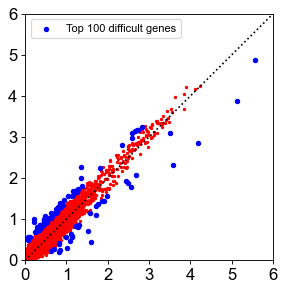

In [4]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_1_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
predict = np.array(predict)
real = np.array(real)

# absolute prediction error for every gene
error = np.abs(predict - real)
top100_idx = np.argsort(error)[-100:]
predict_top100 = predict[top100_idx]
real_top100 = real[top100_idx]

# calculate R2
from sklearn.metrics import r2_score
from scipy.stats import pearsonr as scipy_pearsonr

r2_top100 = r2_score(real_top100, predict_top100)
pearson_top100 = scipy_pearsonr(real_top100, predict_top100)[0]

print("Top 100 difficult genes:")
print("R2 =", r2_top100)
print("Pearson r =", pearson_top100)
r2_list.append(r2_top100)
pearsonr_list.append(pearson_top100)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_top100,
    real_top100,
    s=15,
    c="blue",
    label="Top 100 difficult genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_1_percent_bad_pred_genes.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
Top 100 difficult genes:
R2 = 0.7079587292685177
Pearson r = 0.9142401875172337
4.775421039549066 4.8702583


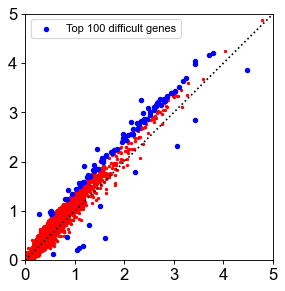

In [5]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_10_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
predict = np.array(predict)
real = np.array(real)

# absolute prediction error for every gene
error = np.abs(predict - real)
top100_idx = np.argsort(error)[-100:]
predict_top100 = predict[top100_idx]
real_top100 = real[top100_idx]

# calculate R2
from sklearn.metrics import r2_score
from scipy.stats import pearsonr as scipy_pearsonr

r2_top100 = r2_score(real_top100, predict_top100)
pearson_top100 = scipy_pearsonr(real_top100, predict_top100)[0]

print("Top 100 difficult genes:")
print("R2 =", r2_top100)
print("Pearson r =", pearson_top100)
r2_list.append(r2_top100)
pearsonr_list.append(pearson_top100)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_top100,
    real_top100,
    s=15,
    c="blue",
    label="Top 100 difficult genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_10_percent_bad_pred_genes.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
Top 100 difficult genes:
R2 = 0.7702606143043504
Pearson r = 0.9074766700752892
5.1374500016968305 4.8702583


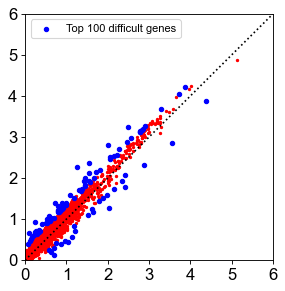

In [6]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_25_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
predict = np.array(predict)
real = np.array(real)

# absolute prediction error for every gene
error = np.abs(predict - real)
top100_idx = np.argsort(error)[-100:]
predict_top100 = predict[top100_idx]
real_top100 = real[top100_idx]

# calculate R2
from sklearn.metrics import r2_score
from scipy.stats import pearsonr as scipy_pearsonr

r2_top100 = r2_score(real_top100, predict_top100)
pearson_top100 = scipy_pearsonr(real_top100, predict_top100)[0]

print("Top 100 difficult genes:")
print("R2 =", r2_top100)
print("Pearson r =", pearson_top100)
r2_list.append(r2_top100)
pearsonr_list.append(pearson_top100)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_top100,
    real_top100,
    s=15,
    c="blue",
    label="Top 100 difficult genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_25_percent_bad_pred_genes.pdf"), bbox_inches="tight")

real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
Top 100 difficult genes:
R2 = 0.6637935720700312
Pearson r = 0.8515796053546969
5.112550019365182 4.8702583


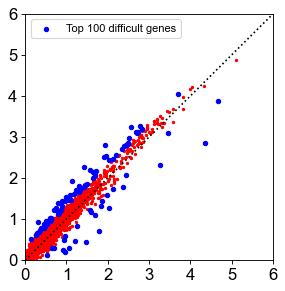

In [7]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_50_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
predict = np.array(predict)
real = np.array(real)

# absolute prediction error for every gene
error = np.abs(predict - real)
top100_idx = np.argsort(error)[-100:]
predict_top100 = predict[top100_idx]
real_top100 = real[top100_idx]

# calculate R2
from sklearn.metrics import r2_score
from scipy.stats import pearsonr as scipy_pearsonr

r2_top100 = r2_score(real_top100, predict_top100)
pearson_top100 = scipy_pearsonr(real_top100, predict_top100)[0]

print("Top 100 difficult genes:")
print("R2 =", r2_top100)
print("Pearson r =", pearson_top100)
r2_list.append(r2_top100)
pearsonr_list.append(pearson_top100)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_top100,
    real_top100,
    s=15,
    c="blue",
    label="Top 100 difficult genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_50_percent_bad_pred_genes.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
Top 100 difficult genes:
R2 = 0.6334883829902254
Pearson r = 0.8496499257565122
4.728633035901662 4.8702583


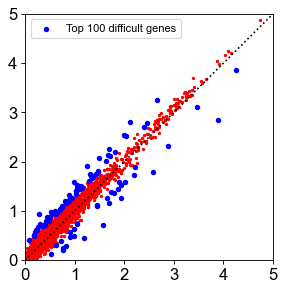

In [8]:

real_data_origin = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==19]
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_70_percent/interception_predict_to_day_19.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
predict = np.array(predict)
real = np.array(real)

# absolute prediction error for every gene
error = np.abs(predict - real)
top100_idx = np.argsort(error)[-100:]
predict_top100 = predict[top100_idx]
real_top100 = real[top100_idx]

# calculate R2
from sklearn.metrics import r2_score
from scipy.stats import pearsonr as scipy_pearsonr

r2_top100 = r2_score(real_top100, predict_top100)
pearson_top100 = scipy_pearsonr(real_top100, predict_top100)[0]

print("Top 100 difficult genes:")
print("R2 =", r2_top100)
print("Pearson r =", pearson_top100)
r2_list.append(r2_top100)
pearsonr_list.append(pearson_top100)
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
plt.scatter(
    predict,
    real,
    s=4,
    c="red"
)
plt.scatter(
    predict_top100,
    real_top100,
    s=15,
    c="blue",
    label="Top 100 difficult genes"
)
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
ticks = np.arange(0, limit+1, 1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.legend(loc="upper left", fontsize=10, frameon=True)
fig.savefig(os.path.join(f"day7_day10_predict_day19_big_training_set_70_percent_bad_pred_genes.pdf"), bbox_inches="tight")

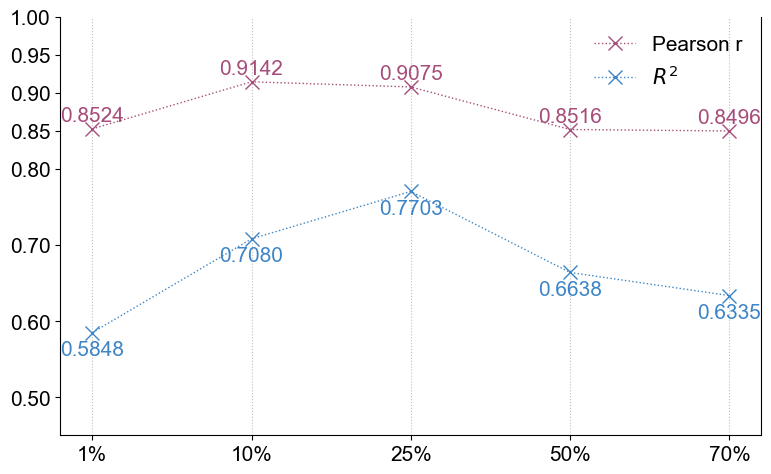

In [9]:
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1

x = ["1%","10%","25%","50%","70%"]
# r2 =[0.9431,0.9493,0.9662,0.9594,0.9735]
# pearsonr = [0.9744,0.9867,0.9878,0.9850,0.9893]
fig,ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    pearsonr_list,
    marker="x", 
    # markerfacecolor="none",
    markersize=10,
    linestyle=":",
    linewidth=1,
    color="#A64D79",
    label="Pearson r"
)

ax.plot(
    x,
    r2_list,
    marker="x",
    # markerfacecolor="none",
    markersize=10,
    linestyle=":",
    linewidth=1,
    color="#3D85C6",
    label=r"$R^2$"
)

# Add numbers above Pearson r points
for i, value in enumerate(pearsonr_list):
    ax.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=15,
        color="#A64D79"
    )

# Add numbers below R² points
for i, value in enumerate(r2_list):
    ax.text(
        i,
        value - 0.01,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=15,
        color="#3D85C6"
    )

# ax.set_yscale("function", functions=(
#     lambda y: np.where(y <= 0.8, y * 0.1, 0.08 + (y - 0.8)),
#     lambda y: np.where(y <= 0.08, y / 0.1, 0.8 + (y - 0.08))
# ))

ax.set_yticks([0.5,0.6,0.7,0.8, 0.85, 0.9, 0.95, 1.0])  # Upper section
ax.set_ylim([0.45,1])
ax.spines["top"].set_visible(False)
ax.legend(frameon=False)
ax.set_axisbelow(True)  # Keep grid lines behind the data
ax.grid(axis="x", linestyle=":", color="gray", linewidth=0.8, alpha=0.5)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_top_100_bad_prediction_genes.pdf"), bbox_inches="tight")

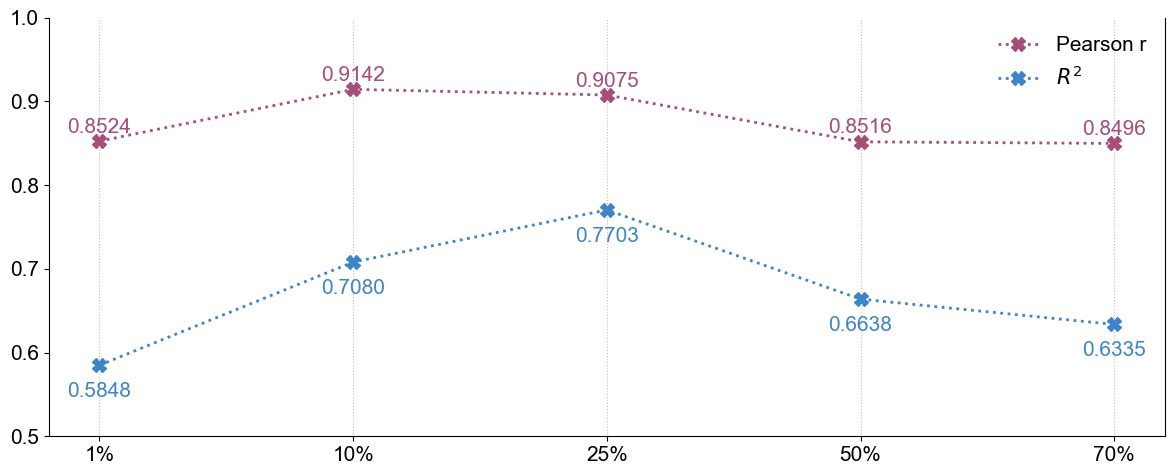

In [10]:
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

# --------------------------------------------------
# Example benchmark data
# Replace these values with your own results
# --------------------------------------------------

x = ["1%","10%","25%","50%","70%"]
# r2_list
# pearsonr_list

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    x,
    pearsonr_list,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="#A64D79",
    label="Pearson r"
)

ax.plot(
    x,
    r2_list,
    marker="X",
    markersize=10,
    linestyle=":",
    linewidth=2,
    color="#3D85C6",
    label=r"$R^2$"
)

# Add numbers above Pearson r points
for i, value in enumerate(pearsonr_list):
    ax.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=15,
        color="#A64D79"
    )

# Add numbers below R² points
for i, value in enumerate(r2_list):
    ax.text(
        i,
        value - 0.02,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=15,
        color="#3D85C6"
    )

ax.set_ylim(0.5, 1.0)
ax.spines["top"].set_visible(False)
ax.legend(frameon=False)
ax.grid(axis="x", linestyle=":", color="gray", linewidth=0.8, alpha=0.5)

plt.tight_layout()
fig.savefig(os.path.join(f"scaling_law_top_100_bad_prediction_genes.pdf"), bbox_inches="tight")